# Dynamic Cluster Curve Review

Loads the `DimensionalityReduction&Clustering` outputs and visualizes median trajectories plus representative example genes for broad clusters and their fine-cluster substructure.


In [1]:
suppressPackageStartupMessages({
  library(dplyr)
  library(tidyr)
  library(tibble)
  library(ggplot2)
  library(patchwork)
  library(RColorBrewer)
})

workspace_notebook_dir <- normalizePath(getwd(), mustWork = TRUE)
OUTPUT_DIR <- Sys.getenv(
  "CHRONOPACK_DIMRED_OUTPUT_DIR",
  file.path(workspace_notebook_dir, "../verification_runs/dimred_executed_render/output")
)
OUTPUT_DIR <- normalizePath(path.expand(OUTPUT_DIR), mustWork = TRUE)

pc_df <- readRDS(file.path(OUTPUT_DIR, "pc_df.new.rds"))
traj_mat <- readRDS(file.path(OUTPUT_DIR, "traj_mat.rds"))
tt <- readRDS(file.path(OUTPUT_DIR, "tt.rds"))

stopifnot(all(rownames(pc_df) %in% rownames(traj_mat)))
traj_mat <- traj_mat[rownames(pc_df), , drop = FALSE]

time_minutes <- tt * length(tt)

cat("pc_df:", paste(dim(pc_df), collapse = " x "), "\n")
cat("traj_mat:", paste(dim(traj_mat), collapse = " x "), "\n")
print(table(pc_df$broad_cluster))


pc_df: 6753 x 35 


traj_mat: 6753 x 97 



  impulse-up_1   impulse-up_2 transient-down   trend-down_1   trend-down_2 
           894            519            333           1977           1210 
      trend-up 
          1820 


In [2]:
cluster_palette <- c(
  "impulse-up_1" = "#F8766D",
  "impulse-up_2" = "#D84A42",
  "trend-up" = "#C29A33",
  "transient-down" = "#8B78C6",
  "trend-down_1" = "#619CFF",
  "trend-down_2" = "#3C6FB6"
)

fine_palette <- grDevices::hcl.colors(24, palette = "Dark 3")

z_row <- function(M) {
  M <- as.matrix(M)
  mu <- rowMeans(M, na.rm = TRUE)
  sd <- matrixStats::rowSds(M, na.rm = TRUE)
  sd[!is.finite(sd) | sd == 0] <- 1
  sweep(sweep(M, 1, mu, "-"), 1, sd, "/")
}

trajectory_long <- function(rows, normalize = FALSE) {
  M <- traj_mat[rows, , drop = FALSE]
  if (normalize) M <- z_row(M)
  as.data.frame(M) %>%
    rownames_to_column("row_id") %>%
    pivot_longer(-row_id, names_to = "time_index", values_to = "value") %>%
    mutate(
      time_index = as.integer(factor(time_index, levels = colnames(M))),
      time = time_minutes[time_index]
    ) %>%
    left_join(pc_df %>% rownames_to_column("row_id") %>% select(row_id, gene, cell_type, broad_cluster, cluster_fine_induced, cluster_fine_repressed, waldStat_1, peak_log2fc), by = "row_id")
}

median_iqr_df <- function(rows, group_col = "broad_cluster", normalize = FALSE) {
  trajectory_long(rows, normalize = normalize) %>%
    group_by(.data[[group_col]], time) %>%
    summarise(
      median = median(value, na.rm = TRUE),
      q25 = quantile(value, 0.25, na.rm = TRUE),
      q75 = quantile(value, 0.75, na.rm = TRUE),
      n = dplyr::n_distinct(row_id),
      .groups = "drop"
    ) %>%
    rename(cluster = .data[[group_col]])
}

select_example_rows <- function(rows, n = 6) {
  pc_df[rows, , drop = FALSE] %>%
    rownames_to_column("row_id") %>%
    arrange(desc(waldStat_1), row_id) %>%
    slice_head(n = n) %>%
    pull(row_id)
}

plot_median_curves <- function(rows, group_col = "broad_cluster", normalize = FALSE, title = NULL, palette = NULL) {
  df <- median_iqr_df(rows, group_col = group_col, normalize = normalize)
  p <- ggplot(df, aes(time, median, color = cluster, fill = cluster)) +
    geom_ribbon(aes(ymin = q25, ymax = q75), alpha = 0.18, color = NA) +
    geom_line(linewidth = 1.1) +
    labs(title = title, x = "Aligned time (min)", y = ifelse(normalize, "Median z trajectory", "Median trajectory"), color = NULL, fill = NULL) +
    theme_classic(base_size = 12)
  if (!is.null(palette)) p <- p + scale_color_manual(values = palette) + scale_fill_manual(values = palette)
  p
}

plot_example_genes <- function(rows, normalize = FALSE, title = NULL, palette = cluster_palette) {
  df <- trajectory_long(rows, normalize = normalize)
  df$label <- paste0(df$gene, " (", df$cell_type, ")")
  ggplot(df, aes(time, value, color = broad_cluster, group = row_id)) +
    geom_line(linewidth = 0.9, alpha = 0.9) +
    facet_wrap(~ label, scales = "free_y", ncol = 3) +
    scale_color_manual(values = palette) +
    labs(title = title, x = "Aligned time (min)", y = ifelse(normalize, "z trajectory", "Trajectory"), color = NULL) +
    theme_classic(base_size = 11) +
    theme(strip.text = element_text(size = 8), legend.position = "bottom")
}


## Broad Clusters


Warning message:
"Use of .data in tidyselect expressions was deprecated in tidyselect 1.2.0.
i Please use `all_of(var)` (or `any_of(var)`) instead of `.data[[var]]`"


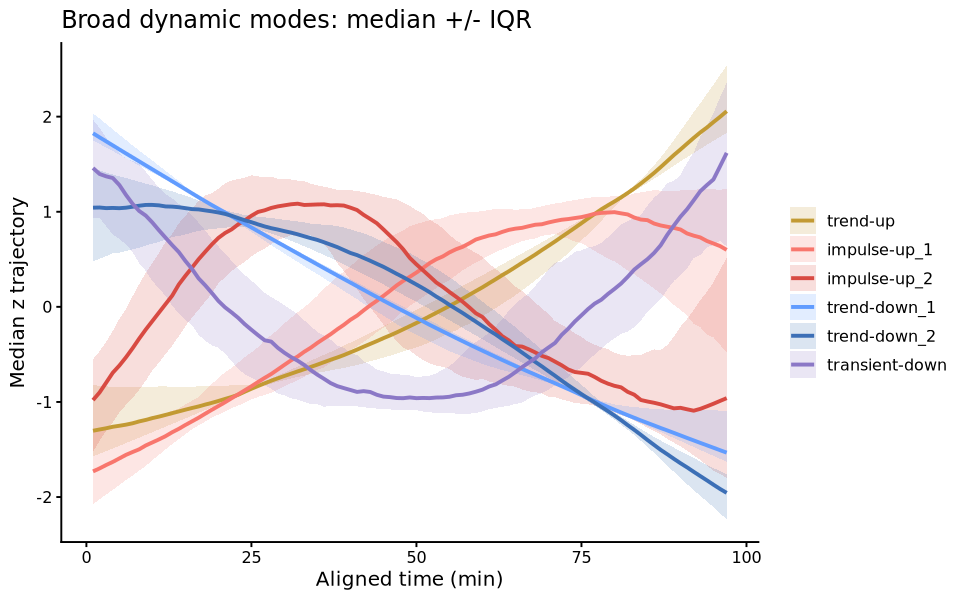

In [3]:
broad_order <- c("trend-up", "impulse-up_1", "impulse-up_2", "trend-down_1", "trend-down_2", "transient-down")
pc_df$broad_cluster <- factor(as.character(pc_df$broad_cluster), levels = broad_order)

options(repr.plot.width = 8, repr.plot.height = 5)
plot_median_curves(rownames(pc_df), group_col = "broad_cluster", normalize = TRUE, title = "Broad dynamic modes: median +/- IQR", palette = cluster_palette)


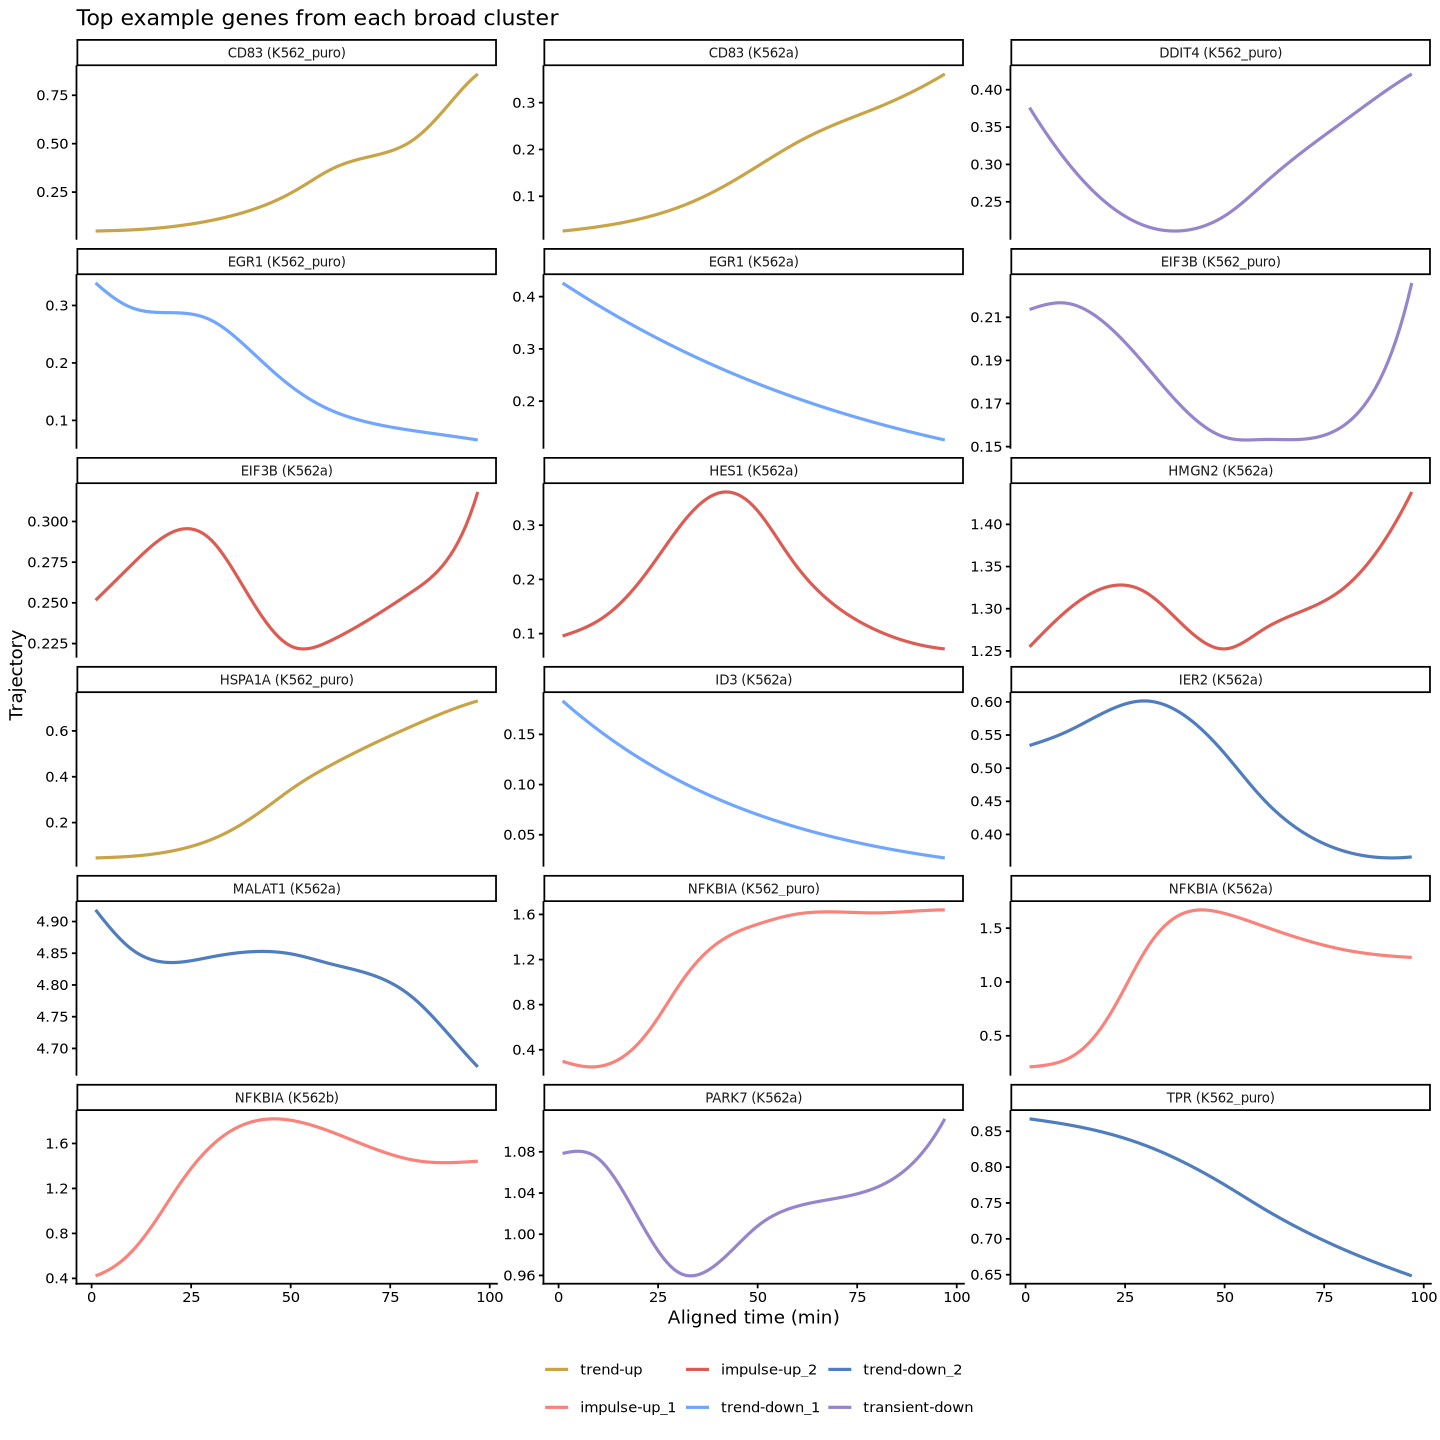

In [4]:
options(repr.plot.width = 12, repr.plot.height = 12)
broad_examples <- unlist(lapply(broad_order, function(cl) {
  rows <- rownames(pc_df)[as.character(pc_df$broad_cluster) == cl]
  select_example_rows(rows, n = 3)
}), use.names = FALSE)
plot_example_genes(broad_examples, normalize = FALSE, title = "Top example genes from each broad cluster")


## Fine Clusters Within Broad Modes


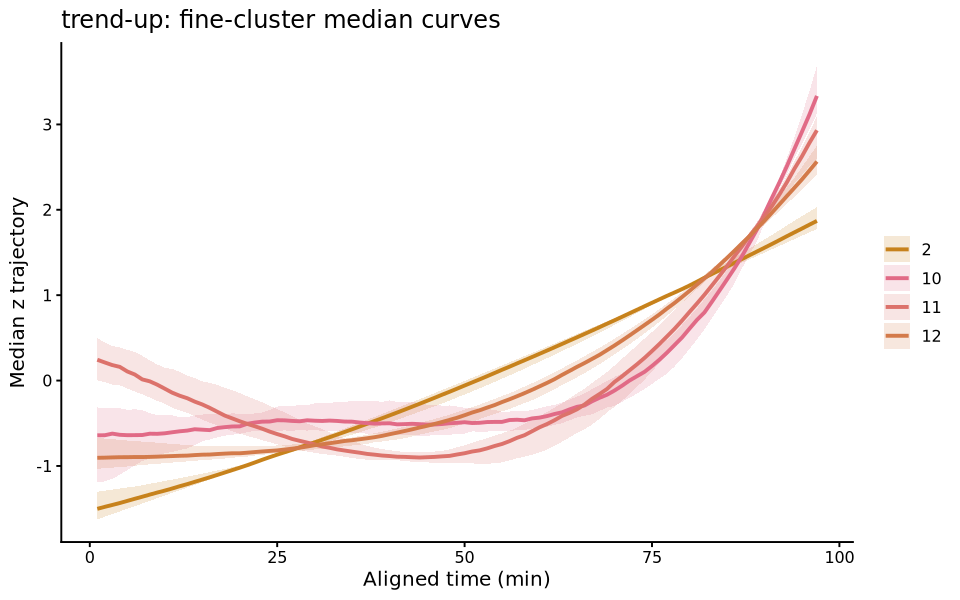

In [5]:
get_fine_col <- function(broad_cluster) {
  if (broad_cluster %in% c("trend-up", "impulse-up_1", "impulse-up_2")) "cluster_fine_induced" else "cluster_fine_repressed"
}

plot_fine_for_broad <- function(broad_cluster, normalize = TRUE) {
  rows <- rownames(pc_df)[as.character(pc_df$broad_cluster) == broad_cluster]
  fine_col <- get_fine_col(broad_cluster)
  df <- pc_df[rows, , drop = FALSE]
  fine_levels <- sort(unique(as.character(df[[fine_col]])))
  fine_levels <- fine_levels[fine_levels != "-1"]
  rows <- rows[as.character(pc_df[rows, fine_col]) %in% fine_levels]
  pal <- setNames(fine_palette[seq_along(fine_levels)], fine_levels)
  plot_median_curves(rows, group_col = fine_col, normalize = normalize, title = paste0(broad_cluster, ": fine-cluster median curves"), palette = pal)
}

options(repr.plot.width = 8, repr.plot.height = 5)
plot_fine_for_broad("trend-up")


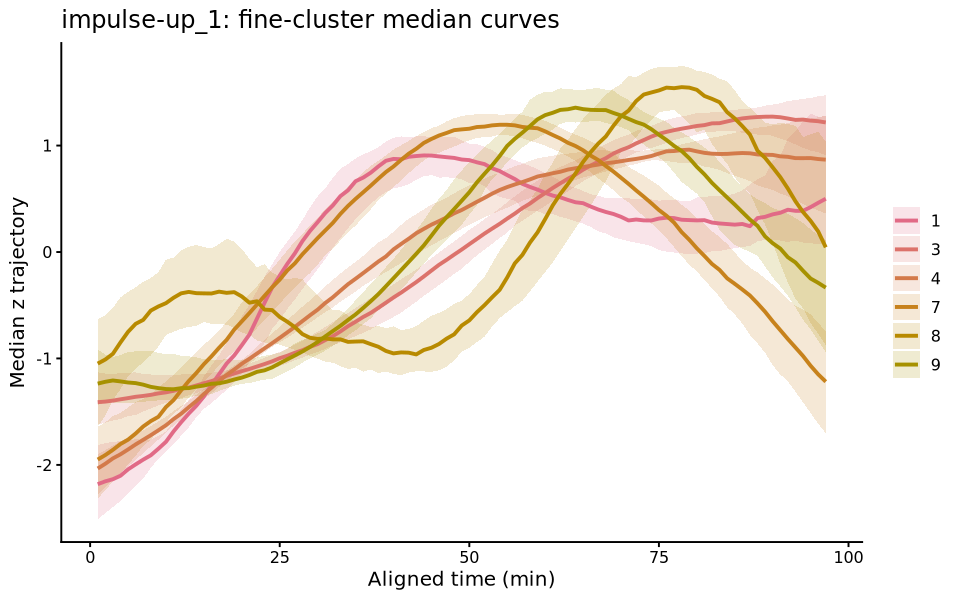

In [6]:
options(repr.plot.width = 8, repr.plot.height = 5)
plot_fine_for_broad("impulse-up_1")


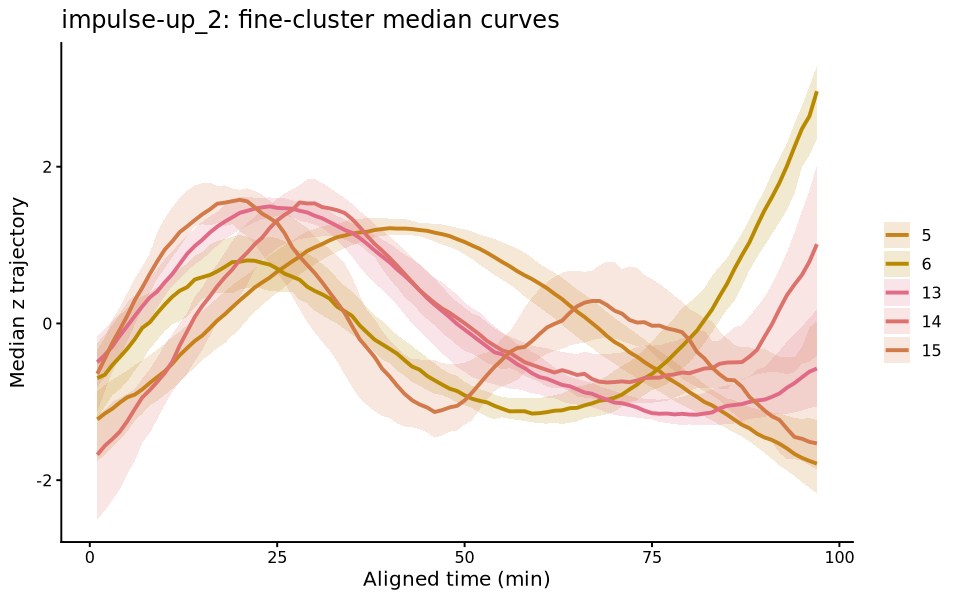

In [7]:
options(repr.plot.width = 8, repr.plot.height = 5)
plot_fine_for_broad("impulse-up_2")


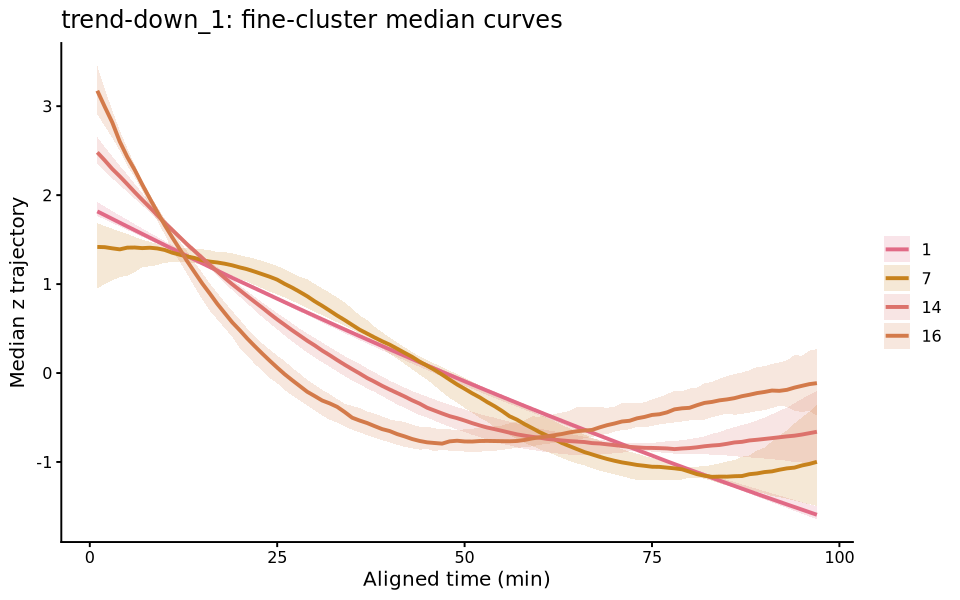

In [8]:
options(repr.plot.width = 8, repr.plot.height = 5)
plot_fine_for_broad("trend-down_1")


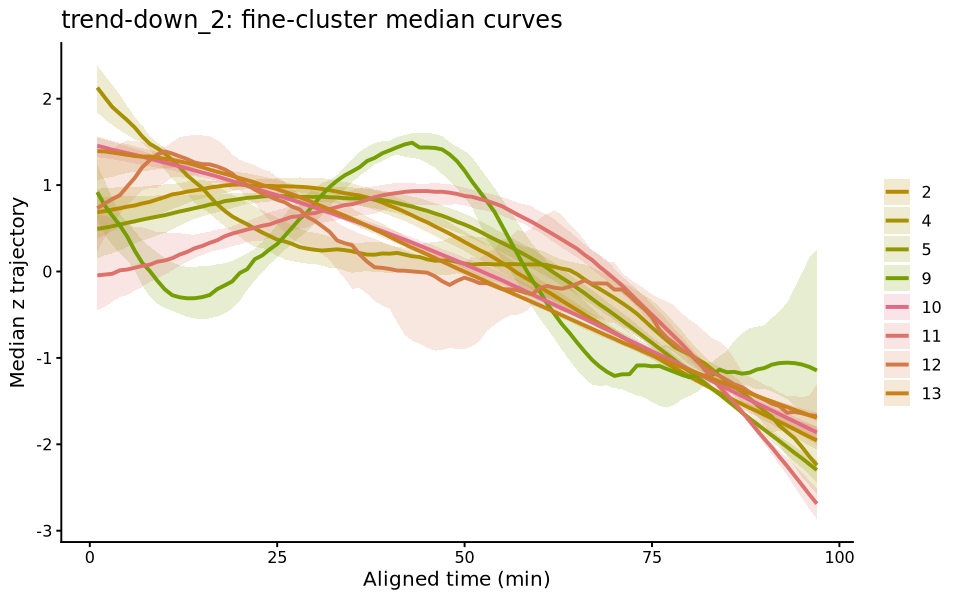

In [9]:
options(repr.plot.width = 8, repr.plot.height = 5)
plot_fine_for_broad("trend-down_2")


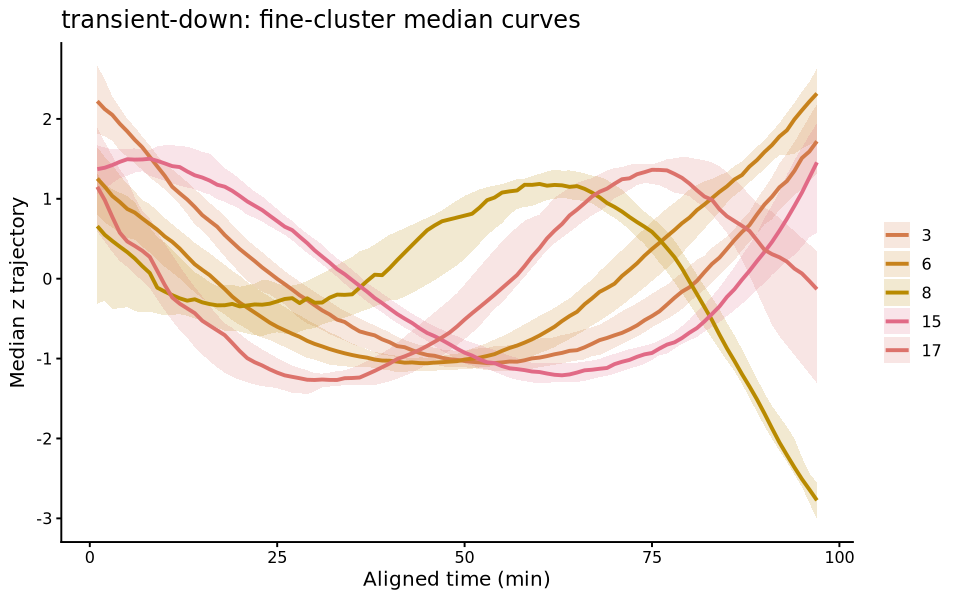

In [10]:
options(repr.plot.width = 8, repr.plot.height = 5)
plot_fine_for_broad("transient-down")


## Example Genes By Fine Cluster


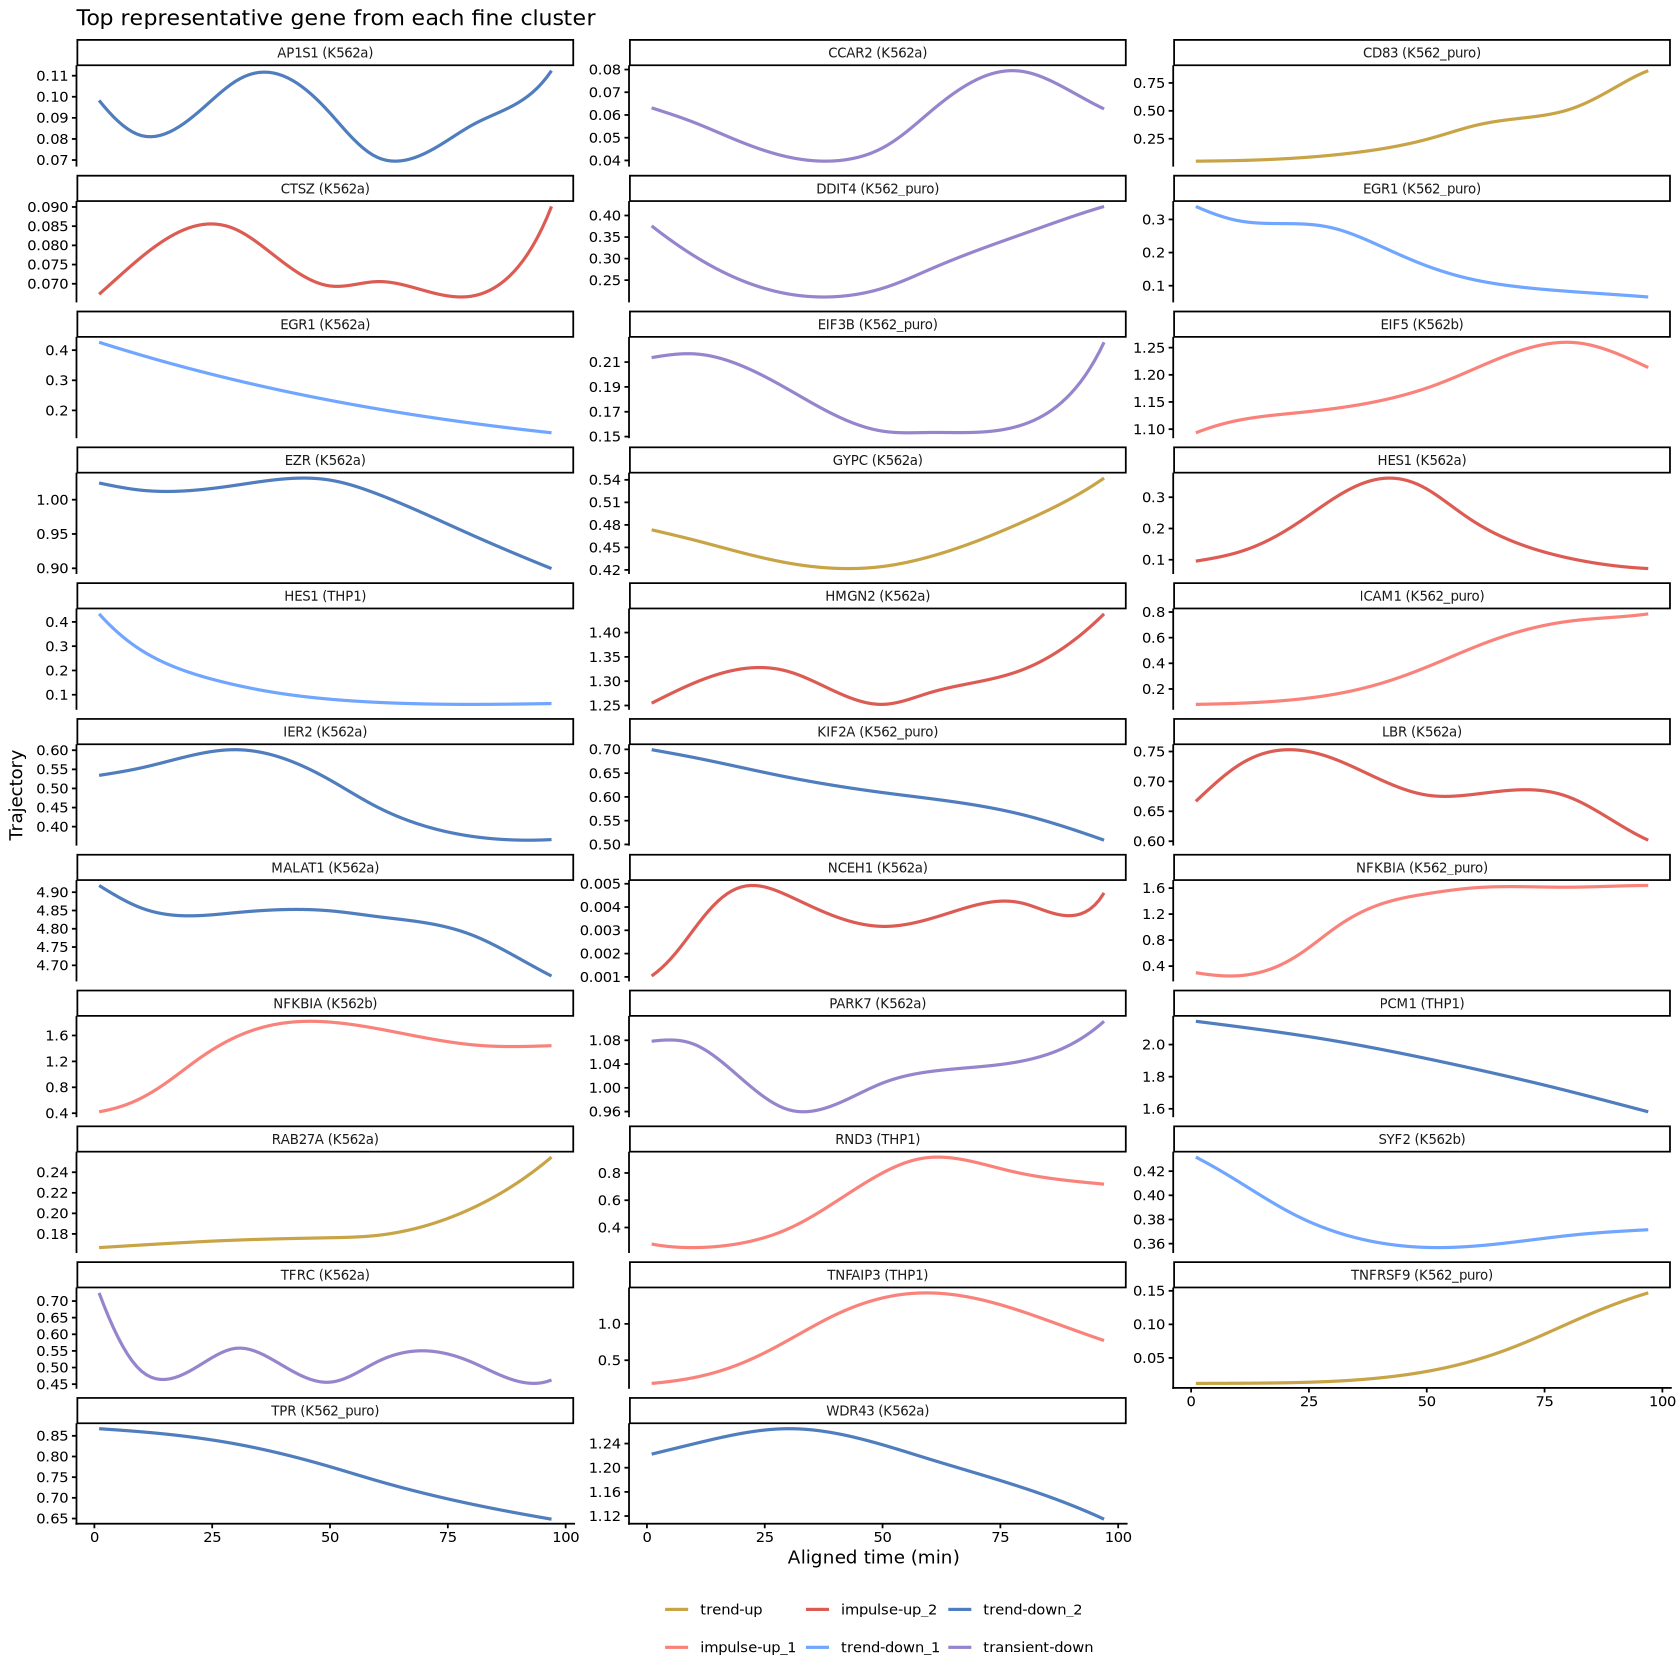

In [11]:
fine_example_rows <- unlist(lapply(broad_order, function(bc) {
  fine_col <- get_fine_col(bc)
  rows_bc <- rownames(pc_df)[as.character(pc_df$broad_cluster) == bc]
  fine_levels <- sort(unique(as.character(pc_df[rows_bc, fine_col])))
  fine_levels <- fine_levels[fine_levels != "-1"]
  unlist(lapply(fine_levels, function(fc) {
    rows <- rows_bc[as.character(pc_df[rows_bc, fine_col]) == fc]
    select_example_rows(rows, n = 1)
  }), use.names = FALSE)
}), use.names = FALSE)

options(repr.plot.width = 14, repr.plot.height = 14)
plot_example_genes(fine_example_rows, normalize = FALSE, title = "Top representative gene from each fine cluster")


In [12]:
example_table <- pc_df[fine_example_rows, , drop = FALSE] %>%
  rownames_to_column("row_id") %>%
  mutate(fine_cluster = ifelse(cluster_fine_induced != "-1", as.character(cluster_fine_induced), as.character(cluster_fine_repressed))) %>%
  select(row_id, gene, cell_type, broad_cluster, fine_cluster, waldStat_1, peak_log2fc, t_onset, t_peak) %>%
  arrange(broad_cluster, fine_cluster, desc(waldStat_1))
example_table


row_id,gene,cell_type,broad_cluster,fine_cluster,waldStat_1,peak_log2fc,t_onset,t_peak
<chr>,<chr>,<chr>,<fct>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
RAB27A_K562a,RAB27A,K562a,trend-up,10,104.19477,0.6777459,23.00000,97.00000
GYPC_K562a,GYPC,K562a,trend-up,11,85.64876,0.2500724,10.00000,97.00000
TNFRSF9_K562_puro,TNFRSF9,K562_puro,trend-up,12,191.52790,3.7167752,41.00000,97.00000
CD83_K562_puro,CD83,K562_puro,trend-up,2,1081.21345,4.7650843,29.00000,97.00000
NFKBIA_K562b,NFKBIA,K562b,impulse-up_1,1,2003.69953,3.2977962,9.00000,46.00000
ICAM1_K562_puro,ICAM1,K562_puro,impulse-up_1,3,958.94064,3.8486178,27.00000,97.00000
NFKBIA_K562_puro,NFKBIA,K562_puro,impulse-up_1,4,2021.13852,3.5794766,18.00000,97.00000
TNFAIP3_THP1,TNFAIP3,THP1,impulse-up_1,7,455.86648,3.9834972,20.00000,90.76923
EIF5_K562b,EIF5,K562b,impulse-up_1,8,190.01420,0.3476645,11.00000,80.00000
